# LesionGraph-Net — Paper-aligned Colab implementation

**Based on:** Akter et al., *LesionGraph-Net: A clinically motivated Graph Neural Network for accurate skin cancer diagnosis using lesion-focused features*, Intelligence-Based Medicine (2026), DOI: 10.1016/j.ibmed.2026.100464.

This notebook implements the paper's reported pipeline as closely as the published description permits: ISIC 2019 subset → 256×256 resizing → black-hat hair removal → LAB-CLAHE → LAB K-means (K=2) → nine lesion features → ANOVA + χ² SelectKBest → Pearson graph (|r| > 0.2) → 3-layer GCN with ConvLSTM1D fusion → FFN classification.

**Important reproducibility notes**
- The paper's Table 2 mentions 224×224, while Section 4.1.1 and Table 8 specify 256×256. This notebook follows the implementation details (256×256).
- The paper reports a 3297-image ISIC 2019 subset (1800 malignant, 1497 benign). You must provide the corresponding image files and metadata; this notebook does not fabricate or download them.
- The paper's architecture description is incomplete in places. The implementation below makes explicit choices for the class/readout node, ConvLSTM1D input sequence, and nine residual FFN blocks. These are paper-aligned engineering interpretations, not a claim of access to the authors' exact source code.
- The paper says the final retained seven features are SIFT, Asymmetry, Solidity/CHR, Circularity, Color Variation, Ellipticity ratio, and Harris. The code uses χ² SelectKBest (k=7) and reports whether its selected set matches that published list.


In [ ]:
# 1. Environment and reproducibility
!pip -q install opencv-contrib-python-headless==4.10.0.84 scikit-learn pandas matplotlib seaborn tqdm networkx

import os, random, glob, warnings, json, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif, chi2
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, confusion_matrix, classification_report, roc_auc_score,
    average_precision_score)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


Device: cpu


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("salviohexia/isic-2019-skin-lesion-images-for-classification")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'isic-2019-skin-lesion-images-for-classification' dataset.
Path to dataset files: /kaggle/input/isic-2019-skin-lesion-images-for-classification


In [ ]:
import os

for root, dirs, files in os.walk(path):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("Sample files:", files[:5])

Folder: /kaggle/input/isic-2019-skin-lesion-images-for-classification
Number of files: 2
Sample files: ['ISIC_2019_Training_GroundTruth.csv', 'ISIC_2019_Training_Metadata.csv']
Folder: /kaggle/input/isic-2019-skin-lesion-images-for-classification/MEL
Number of files: 4522
Sample files: ['ISIC_0014233_downsampled.jpg', 'ISIC_0056156.jpg', 'ISIC_0066845.jpg', 'ISIC_0054024.jpg', 'ISIC_0070711.jpg']
Folder: /kaggle/input/isic-2019-skin-lesion-images-for-classification/VASC
Number of files: 253
Sample files: ['ISIC_0068877.jpg', 'ISIC_0029889.jpg', 'ISIC_0055280.jpg', 'ISIC_0033123.jpg', 'ISIC_0066461.jpg']
Folder: /kaggle/input/isic-2019-skin-lesion-images-for-classification/SCC
Number of files: 628
Sample files: ['ISIC_0028872.jpg', 'ISIC_0058690.jpg', 'ISIC_0055870.jpg', 'ISIC_0072158.jpg', 'ISIC_0072135.jpg']
Folder: /kaggle/input/isic-2019-skin-lesion-images-for-classification/DF
Number of files: 239
Sample files: ['ISIC_0070680.jpg', 'ISIC_0070730.jpg', 'ISIC_0064930.jpg', 'ISIC_0057

## 2. Mount Drive and configure ISIC 2019 data

Prepare a metadata CSV with at least `image_id`, `lesion_id`, and `dx` columns. Images may be in one or more folders. The ISIC 2019 diagnostic codes used by the paper are `MEL, NV, BCC, AK, BKL, DF, VASC, SCC`; `UNK` is excluded.

In [ ]:
# Use the downloaded kagglehub dataset path
DATA_ROOT = '/kaggle/input/isic-2019-skin-lesion-images-for-classification'
METADATA_CSV = os.path.join(DATA_ROOT, 'ISIC_2019_Training_Metadata.csv')
GROUND_TRUTH_CSV = os.path.join(DATA_ROOT, 'ISIC_2019_Training_GroundTruth.csv')

# Include all subdirectory image folders from the kagglehub path
IMAGE_DIRS = [
    os.path.join(DATA_ROOT, 'MEL'),
    os.path.join(DATA_ROOT, 'VASC'),
    os.path.join(DATA_ROOT, 'SCC'),
    os.path.join(DATA_ROOT, 'DF'),
    os.path.join(DATA_ROOT, 'NV'),
    os.path.join(DATA_ROOT, 'BKL'),
    os.path.join(DATA_ROOT, 'BCC'),
    os.path.join(DATA_ROOT, 'AK')
]
FEATURE_CSV = '/content/lesiongraph_features.csv'

# Load demographic metadata and ground truth classes
metadata = pd.read_csv(METADATA_CSV)
ground_truth = pd.read_csv(GROUND_TRUTH_CSV)

# The Kaggle ground truth uses 'image' instead of 'image_id', let's map it if needed
if 'image' in ground_truth.columns and 'image_id' not in ground_truth.columns:
    ground_truth = ground_truth.rename(columns={'image': 'image_id'})
if 'image' in metadata.columns and 'image_id' not in metadata.columns:
    metadata = metadata.rename(columns={'image': 'image_id'})

# Merge demographic metadata with diagnosis ground truth classes
metadata = pd.merge(metadata, ground_truth, on='image_id', how='inner')

# Create a 'dx' column based on the target class columns if 'dx' is not explicitly present
class_cols = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']
if 'dx' not in metadata.columns and all(col in metadata.columns for col in class_cols):
    # Extract diagnostic class by finding which one is 1.0
    metadata['dx'] = metadata[class_cols].idxmax(axis=1)

# Ensure lesion_id exists (if missing in standard metadata, fallback to image_id to prevent duplicates filtering crash)
if 'lesion_id' not in metadata.columns:
    metadata['lesion_id'] = metadata['image_id']

print(metadata.shape, metadata.columns.tolist())
assert {'image_id','lesion_id','dx'}.issubset(metadata.columns), \
    'Metadata must contain image_id, lesion_id, dx columns.'

(25331, 15) ['image_id', 'age_approx', 'anatom_site_general', 'lesion_id', 'sex', 'MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK', 'dx']


## 3. Image lookup and label mapping

Paper mapping: malignant = MEL, BCC, SCC, AK; benign = NV, BKL, DF, VASC. Unknown diagnosis is excluded. The paper retains one image per lesion ID to reduce leakage.

In [ ]:
image_lookup = {}
for folder in IMAGE_DIRS:
    if os.path.isdir(folder):
        for p in glob.glob(os.path.join(folder, '**', '*'), recursive=True):
            if p.lower().endswith(('.jpg','.jpeg','.png')):
                image_lookup[os.path.splitext(os.path.basename(p))[0]] = p
print('Images indexed:', len(image_lookup))

MALIGNANT = {'MEL','BCC','SCC','AK'}
BENIGN = {'NV','BKL','DF','VASC'}
metadata['dx'] = metadata['dx'].astype(str).str.upper()
metadata = metadata[metadata['dx'].isin(MALIGNANT | BENIGN)].copy()
metadata['label'] = metadata['dx'].map(lambda z: 1 if z in MALIGNANT else 0)
metadata = metadata.drop_duplicates('lesion_id', keep='first').reset_index(drop=True)
metadata['image_path'] = metadata['image_id'].astype(str).map(image_lookup)
metadata = metadata.dropna(subset=['image_path']).reset_index(drop=True)
print('Usable one-image-per-lesion rows:', len(metadata))
print(metadata['label'].value_counts().rename(index={0:'Benign',1:'Malignant'}))


Images indexed: 25331
Usable one-image-per-lesion rows: 11848
label
Benign       8613
Malignant    3235
Name: count, dtype: int64


## 4. Preprocessing: resize, hair removal, CLAHE

The black-hat kernel is 17×17 elliptical; threshold = 10; dilation kernel = 3×3; Telea inpainting radius = 3. CLAHE is applied only to the L channel in LAB (clip limit 2.0, tile grid 8×8).

In [ ]:
IMG_SIZE = (256, 256)
def preprocess_image(image_bgr):
    image = cv2.resize(image_bgr, IMG_SIZE, interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (17,17))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, hair_mask = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    dil_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))
    hair_mask = cv2.dilate(hair_mask, dil_kernel, iterations=1)
    cleaned = cv2.inpaint(image, hair_mask, 3, cv2.INPAINT_TELEA)
    lab = cv2.cvtColor(cleaned, cv2.COLOR_BGR2LAB)
    L, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    enhanced = cv2.cvtColor(cv2.merge((clahe.apply(L),a,b)), cv2.COLOR_LAB2BGR)
    return enhanced, hair_mask


## 5. K-means ROI segmentation (LAB, K=2)

Pixels are used in native LAB range. The cluster with lower mean L is selected as lesion foreground, then opening, closing, and largest connected component are applied.

In [ ]:
def segment_lesion(enhanced_bgr):
    lab = cv2.cvtColor(enhanced_bgr, cv2.COLOR_BGR2LAB)
    h,w = lab.shape[:2]
    pixels = np.float32(lab.reshape((-1,3)))
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    cv2.setRNGSeed(SEED)
    _, labels, _ = cv2.kmeans(pixels, 2, None, criteria, 10, cv2.KMEANS_PP_CENTERS)
    labels = labels.reshape(h,w)
    means = [float(lab[:,:,0][labels == k].mean()) if np.any(labels==k) else np.inf for k in range(2)]
    fg = int(np.argmin(means))
    mask = (labels == fg).astype(np.uint8)*255
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    n, comp, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if n <= 1: raise ValueError('No foreground component after K-means post-processing')
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    final_mask = (comp == largest).astype(np.uint8)*255
    return final_mask


### Optional: evaluate cluster count (K=2…10)

The article reports inertia and silhouette-score evaluation over K=2…10 and selects K=2. This diagnostic is optional because silhouette scoring over all 256×256 pixels is expensive.

In [ ]:
# Optional single-image diagnostic; run after loading an image.
# sample up to 10,000 LAB pixels to keep silhouette calculation tractable.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def evaluate_kmeans_k(enhanced_bgr, sample_size=10000):
    lab = cv2.cvtColor(enhanced_bgr, cv2.COLOR_BGR2LAB).reshape(-1,3).astype(np.float32)
    rng = np.random.default_rng(SEED)
    sample = lab[rng.choice(len(lab), min(sample_size,len(lab)), replace=False)]
    records=[]
    for k in range(2,11):
        km=KMeans(n_clusters=k,init='k-means++',n_init=10,random_state=SEED)
        labels=km.fit_predict(sample)
        records.append({'K':k,'inertia':km.inertia_,'silhouette':silhouette_score(sample,labels)})
    result=pd.DataFrame(records); display(result)
    result.plot(x='K',y='silhouette',marker='o',title='Silhouette score by K'); plt.show()
    return result


## 6. Extract the nine features from Table 4

- Solidity/convex hull ratio = contour area / convex hull area
- SIFT and Harris = keypoint/corner count divided by lesion area
- Ellipticity ratio = fitted ellipse area / lesion area
- Circularity = 4πA/P²
- WHR = bounding-box width / height
- Asymmetry = normalized difference between the two mask halves after alignment to the principal axis
- Color variation = standard deviation of grayscale intensities inside ROI
- Compactness = P²/(4πA)

The paper does not fully specify the Harris corner thresholding rule; this implementation uses a documented relative-response threshold (1% of the ROI maximum) to count detected corners.

In [ ]:
FEATURE_NAMES = ['Solidity','SIFT','Harris','Ellipticity','Circularity','WHR','Asymmetry','Color_Variation','Compactness']

def extract_features(image_bgr, mask):
    binary = (mask > 0).astype(np.uint8)*255
    contours,_ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours: raise ValueError('No lesion contour')
    contour = max(contours, key=cv2.contourArea)
    area = float(cv2.contourArea(contour)); perimeter = float(cv2.arcLength(contour, True))
    if area <= 0 or perimeter <= 0: raise ValueError('Degenerate lesion contour')
    hull = cv2.convexHull(contour); hull_area = float(cv2.contourArea(hull))
    solidity = area/hull_area if hull_area > 0 else 0.0

    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    sift = cv2.SIFT_create()
    keypoints = sift.detect(gray, binary)
    sift_density = len(keypoints)/area

    gray_f = np.float32(gray)
    harris = cv2.cornerHarris(gray_f, 2, 3, 0.04)
    roi_harris = np.maximum(harris[binary>0], 0)
    harris_count = int(np.sum(roi_harris > (0.01*roi_harris.max()))) if roi_harris.size and roi_harris.max()>0 else 0
    harris_density = harris_count/area

    if len(contour) >= 5:
        ellipse = cv2.fitEllipse(contour)
        axis_a,axis_b = ellipse[1]
        ellipse_area = np.pi*axis_a*axis_b/4.0
        ellipticity = float(ellipse_area/area)
    else: ellipticity = 0.0

    circularity = float(4*np.pi*area/(perimeter**2))
    x,y,w,h = cv2.boundingRect(contour)
    whr = float(w/h) if h else 0.0

    # Principal axis from foreground pixel coordinates; rotate major axis horizontally.
    ys,xs = np.where(binary>0)
    coords = np.column_stack([xs,ys]).astype(np.float32)
    center = coords.mean(axis=0)
    cov = np.cov((coords-center).T)
    vals,vecs = np.linalg.eigh(cov)
    major = vecs[:,np.argmax(vals)]
    angle = np.degrees(np.arctan2(major[1],major[0]))
    rot = cv2.getRotationMatrix2D(tuple(center), angle, 1.0)
    rotated = cv2.warpAffine(binary, rot, (binary.shape[1],binary.shape[0]), flags=cv2.INTER_NEAREST)
    left = int(np.count_nonzero(rotated[:, :rotated.shape[1]//2]))
    right = int(np.count_nonzero(rotated[:, rotated.shape[1]//2:]))
    asymmetry = abs(left-right)/(left+right) if left+right else 0.0

    color_variation = float(np.std(gray[binary>0]))
    compactness = float((perimeter**2)/(4*np.pi*area))
    vals = [solidity,sift_density,harris_density,ellipticity,circularity,whr,asymmetry,color_variation,compactness]
    if not np.all(np.isfinite(vals)): raise ValueError('Non-finite feature value')
    return dict(zip(FEATURE_NAMES, vals))


## 7. Batch feature extraction

This can take a long time. It saves progress only at the end; use a smaller metadata subset first to validate your paths and pipeline.

In [ ]:
rows, failures = [], []
for row in tqdm(metadata.itertuples(index=False), total=len(metadata), desc='Feature extraction'):
    try:
        img = cv2.imread(row.image_path)
        if img is None: raise ValueError('Image could not be read')
        enhanced, hair_mask = preprocess_image(img)
        lesion_mask = segment_lesion(enhanced)
        feats = extract_features(enhanced, lesion_mask)
        rows.append({'image_id':row.image_id,'lesion_id':row.lesion_id,'dx':row.dx,'label':int(row.label),**feats})
    except Exception as e:
        failures.append({'image_id':row.image_id,'error':str(e)})

features_df = pd.DataFrame(rows)
print('Extracted:',len(features_df),'Failed:',len(failures))
if features_df.empty: raise RuntimeError('No features extracted. Verify dataset paths and image format.')
features_df.to_csv(FEATURE_CSV,index=False)
# Save failures log to the writable /content/ folder instead of the read-only DATA_ROOT
pd.DataFrame(failures).to_csv('/content/feature_extraction_errors.csv',index=False)
display(features_df.head())

Feature extraction:   0%|          | 0/11848 [00:00<?, ?it/s]

Extracted: 11848 Failed: 0


,image_id,lesion_id,dx,label,Solidity,SIFT,Harris,Ellipticity,Circularity,WHR,Asymmetry,Color_Variation,Compactness
0,ISIC_0000000,NaN,NV,0,0.936361,0.001671,0.082643,1.051555,0.620242,1.051546,0.040495,26.848511,1.612275
1,ISIC_0012653_downsampled,MSK4_0011169,NV,0,0.954951,0.000467,0.227931,1.016162,0.624635,0.421687,0.776586,21.756191,1.600934
2,ISIC_0012654_downsampled,MSK4_0011170,NV,0,0.903846,0.000000,0.333333,1.428789,0.437179,0.474576,1.000000,12.157103,2.287395
3,ISIC_0012655_downsampled,MSK4_0011171,NV,0,0.957097,0.001494,0.189765,1.018465,0.736185,0.561404,0.203980,35.628626,1.358354
4,ISIC_0012656_downsampled,MSK4_0011172,NV,0,0.941438,0.001758,0.185515,1.034867,0.695566,0.683673,0.158863,28.150563,1.437679


## 8. Train/validation/test split (80/10/10)

The paper uses a random 80/10/10 split and one image per lesion. This notebook stratifies by binary label with seed 42. Split order here is train, validation, test.

In [ ]:
df = pd.read_csv(FEATURE_CSV)
df = df.replace([np.inf,-np.inf],np.nan).dropna(subset=FEATURE_NAMES+['label','lesion_id']).reset_index(drop=True)
X_all = df[FEATURE_NAMES].astype(float)
y_all = df['label'].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(X_all,y_all,test_size=0.20,random_state=SEED,stratify=y_all)
X_val, X_test, y_val, y_test = train_test_split(X_temp,y_temp,test_size=0.50,random_state=SEED,stratify=y_temp)
print('Train/Val/Test:',len(X_train),len(X_val),len(X_test))
print('Class counts (train):',y_train.value_counts().to_dict())


Train/Val/Test: 9477 1185 1185
Class counts (train): {0: 6889, 1: 2588}


## 9. Feature selection: ANOVA F-test + χ² SelectKBest

The paper first analyzes all nine features using ANOVA F-test, then applies SelectKBest with χ² scoring and retains seven. χ² requires non-negative values, so MinMax scaling is fitted on training data only. The selected feature list is learned on training data and applied unchanged to validation/test.

In [ ]:
anova = SelectKBest(score_func=f_classif, k='all').fit(X_train,y_train)
anova_scores = pd.Series(anova.scores_,index=FEATURE_NAMES).sort_values(ascending=False)
display(anova_scores.to_frame('ANOVA_F_score'))

chi_scaler = MinMaxScaler()
Xtr_nonneg = chi_scaler.fit_transform(X_train)
Xva_nonneg = chi_scaler.transform(X_val)
Xte_nonneg = chi_scaler.transform(X_test)
chi_selector = SelectKBest(score_func=chi2,k=7).fit(Xtr_nonneg,y_train)
selected_features = np.array(FEATURE_NAMES)[chi_selector.get_support()]
print('χ²-selected 7 features:',selected_features.tolist())
PAPER_SEVEN = {'SIFT','Asymmetry','Solidity','Circularity','Color_Variation','Ellipticity','Harris'}
print('Matches paper-reported seven:', set(selected_features)==PAPER_SEVEN)
X_train_selected = chi_selector.transform(Xtr_nonneg)
X_val_selected = chi_selector.transform(Xva_nonneg)
X_test_selected = chi_selector.transform(Xte_nonneg)

# The paper states graph normalization parameters are derived from training data only.
node_scaler = StandardScaler()
X_train_selected = node_scaler.fit_transform(X_train_selected)
X_val_selected = node_scaler.transform(X_val_selected)
X_test_selected = node_scaler.transform(X_test_selected)


,ANOVA_F_score
Solidity,506.214516
Circularity,442.585927
Compactness,419.645960
Harris,312.973585
WHR,114.617889
SIFT,79.314844
Asymmetry,35.831540
Color_Variation,30.820564
Ellipticity,0.118461


χ²-selected 7 features: ['Solidity', 'SIFT', 'Harris', 'Circularity', 'Asymmetry', 'Color_Variation', 'Compactness']
Matches paper-reported seven: False


## 10. Pearson correlation graph (training data only)

Undirected weighted graph; keep an edge only when `abs(r) > 0.2`; edge weight = `abs(r)`. The same training-derived graph is used for validation and test. A self-loop is added for stable message passing.

Feature nodes: 7 edges: 9


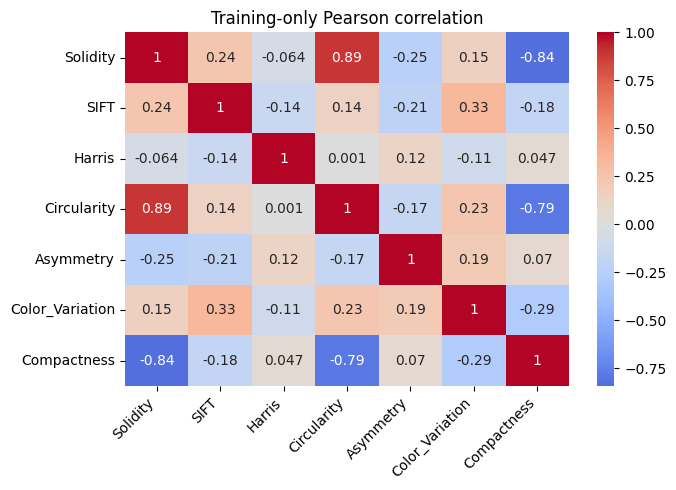

In [ ]:
corr = pd.DataFrame(X_train_selected,columns=selected_features).corr().fillna(0).to_numpy(dtype=np.float32)
num_features = len(selected_features)
A_feat = np.zeros((num_features,num_features),dtype=np.float32)
W_feat = np.zeros_like(A_feat)
for i in range(num_features):
    for j in range(i+1,num_features):
        r = float(corr[i,j])
        if abs(r) > 0.20:
            A_feat[i,j] = A_feat[j,i] = 1.0
            W_feat[i,j] = W_feat[j,i] = abs(r)
np.fill_diagonal(A_feat,1.0)
np.fill_diagonal(W_feat,1.0)
print('Feature nodes:',num_features,'edges:',int(np.triu(A_feat,1).sum()))
plt.figure(figsize=(7,5)); sns.heatmap(corr,xticklabels=selected_features,yticklabels=selected_features,annot=True,cmap='coolwarm',center=0); plt.title('Training-only Pearson correlation'); plt.xticks(rotation=45,ha='right'); plt.tight_layout(); plt.show()


## 11. LesionGraph-Net model

Paper-described elements implemented here:
- Seven feature nodes plus one `Class_C` readout node (8 nodes total).
- Scalar node values projected to 64 dimensions by a preprocessing FFN.
- Three weighted message-passing/GCN layers with tanh updates; layer-wise embeddings form the sequence for ConvLSTM1D.
- Class node connected to all feature nodes as an explicit readout convention (the paper describes a Class_C node but does not fully specify its edge construction).
- Post-processing FFN with nine residual dense/dropout/batch-normalization blocks and a 2-class output.

ConvLSTM1D is implemented as a convolutional LSTM cell over the sequence of GCN-layer embeddings. This is a documented implementation interpretation because the article does not publish a full layer-by-layer tensor specification.

In [ ]:
class ConvLSTM1DCell(nn.Module):
    def __init__(self, channels, kernel_size=3):
        super().__init__()
        self.padding = kernel_size//2
        self.conv = nn.Conv1d(2*channels,4*channels,kernel_size,padding=self.padding)
    def forward(self,x,h,c):
        z = self.conv(torch.cat([x,h],dim=1))
        i,f,o,g = torch.chunk(z,4,dim=1)
        i,f,o = torch.sigmoid(i),torch.sigmoid(f),torch.sigmoid(o)
        g = torch.tanh(g)
        c_new = f*c + i*g
        h_new = o*torch.tanh(c_new)
        return h_new,c_new

class ResidualFFNBlock(nn.Module):
    def __init__(self,dim=64,dropout=0.3):
        super().__init__()
        self.fc = nn.Linear(dim,dim)
        self.bn = nn.BatchNorm1d(dim)
        self.drop = nn.Dropout(dropout)
    def forward(self,x):
        z = self.fc(x)
        # BatchNorm normally uses batch statistics; fall back to running stats for a final singleton batch.
        if self.training and z.shape[0] == 1:
            z = F.batch_norm(z, self.bn.running_mean, self.bn.running_var, self.bn.weight, self.bn.bias, training=False, eps=self.bn.eps)
        else:
            z = self.bn(z)
        z = F.elu(z)
        z = self.drop(z)
        return F.elu(x+z)

class LesionGraphNet(nn.Module):
    def __init__(self,n_features,hidden=64,dropout=0.3,n_ffn_blocks=9):
        super().__init__()
        self.input_projection = nn.Sequential(nn.Linear(1,hidden),nn.BatchNorm1d(hidden),nn.ELU())
        self.gcn_weights = nn.ModuleList([nn.Linear(hidden,hidden) for _ in range(3)])
        self.gcn_self = nn.ModuleList([nn.Linear(hidden,hidden) for _ in range(3)])
        self.convlstm = ConvLSTM1DCell(hidden, kernel_size=3)
        self.post_ffn = nn.ModuleList([ResidualFFNBlock(hidden,dropout) for _ in range(n_ffn_blocks)])
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden,2)
        self.n_features = n_features
    def forward(self,x,adj):
        # x: batch x 7 feature nodes x 1; add unlabeled Class_C readout node
        b = x.shape[0]
        class_node = torch.zeros((b,1,1),device=x.device,dtype=x.dtype)
        x = torch.cat([x,class_node],dim=1)
        h = self.input_projection(x.reshape(-1,1)).reshape(b,self.n_features+1,-1)
        layer_states=[]
        for self_fc, neigh_fc in zip(self.gcn_self,self.gcn_weights):
            neigh = torch.matmul(adj,h)
            h = torch.tanh(self_fc(h)+neigh_fc(neigh))
            layer_states.append(h)
            h = self.dropout(h)
        # ConvLSTM1D over GCN-depth sequence; B x C x sequence_length
        seq = torch.stack(layer_states,dim=-1)  # B x nodes x hidden x 3
        seq = seq.permute(0,1,2,3).reshape(b*(self.n_features+1),-1,3)
        h0 = torch.zeros_like(seq)
        c0 = torch.zeros_like(seq)
        fused,_ = self.convlstm(seq,h0,c0)
        fused = fused[:,:,-1].reshape(b,self.n_features+1,-1)
        readout = fused[:,-1,:]
        for block in self.post_ffn: readout = block(readout)
        return self.classifier(readout)

# Weighted adjacency for 7 feature nodes + class readout node.
# Explicit convention: Class_C is connected to every selected feature node.
A8 = np.zeros((num_features+1,num_features+1),dtype=np.float32)
A8[:num_features,:num_features] = W_feat
A8[num_features,:num_features] = 1.0
A8[:num_features,num_features] = 1.0
A8[num_features,num_features] = 1.0
# Symmetric GCN normalization with weighted adjacency
D = A8.sum(axis=1)
D_inv = np.diag(1.0/np.sqrt(np.maximum(D,1e-8)))
A_norm = D_inv @ A8 @ D_inv
A_tensor = torch.tensor(A_norm,dtype=torch.float32,device=device)

model = LesionGraphNet(n_features=num_features,hidden=64,dropout=0.3,n_ffn_blocks=9).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(),lr=0.01)
print(model)


LesionGraphNet(
  (input_projection): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ELU(alpha=1.0)
  )
  (gcn_weights): ModuleList(
    (0-2): 3 x Linear(in_features=64, out_features=64, bias=True)
  )
  (gcn_self): ModuleList(
    (0-2): 3 x Linear(in_features=64, out_features=64, bias=True)
  )
  (convlstm): ConvLSTM1DCell(
    (conv): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
  )
  (post_ffn): ModuleList(
    (0-8): 9 x ResidualFFNBlock(
      (fc): Linear(in_features=64, out_features=64, bias=True)
      (bn): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (drop): Dropout(p=0.3, inplace=False)
    )
  )
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=64, out_features=2, bias=True)
)


## 12. Train for 250 epochs, batch size 64, SGD lr=0.01

The paper reports 250 epochs, batch size 64, dropout 0.3, SGD and learning rate 0.01. Best validation checkpoint is retained. No test-set tuning is performed.

In [ ]:
def make_loader(X,y,shuffle):
    xt = torch.tensor(np.asarray(X,dtype=np.float32)[:,:,None])
    yt = torch.tensor(np.asarray(y,dtype=np.int64))
    return DataLoader(TensorDataset(xt,yt),batch_size=64,shuffle=shuffle)
train_loader = make_loader(X_train_selected,y_train,True)
val_loader = make_loader(X_val_selected,y_val,False)
test_loader = make_loader(X_test_selected,y_test,False)

EPOCHS=250
best_val=float('inf'); best_state=None
history={'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[]}
for epoch in range(EPOCHS):
    model.train(); tr_loss=0; tr_correct=0; tr_total=0
    for xb,yb in train_loader:
        xb,yb=xb.to(device),yb.to(device)
        optimizer.zero_grad(); logits=model(xb,A_tensor); loss=criterion(logits,yb)
        loss.backward(); optimizer.step()
        tr_loss += loss.item()*len(yb); tr_correct += (logits.argmax(1)==yb).sum().item(); tr_total += len(yb)
    model.eval(); va_loss=0; va_correct=0; va_total=0
    with torch.no_grad():
        for xb,yb in val_loader:
            xb,yb=xb.to(device),yb.to(device); logits=model(xb,A_tensor); loss=criterion(logits,yb)
            va_loss += loss.item()*len(yb); va_correct += (logits.argmax(1)==yb).sum().item(); va_total += len(yb)
    tr_loss/=tr_total; va_loss/=va_total
    history['train_loss'].append(tr_loss); history['val_loss'].append(va_loss)
    history['train_acc'].append(tr_correct/tr_total); history['val_acc'].append(va_correct/va_total)
    if va_loss < best_val:
        best_val=va_loss; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    if (epoch+1)%10==0:
        print(f'Epoch {epoch+1:03d}/{EPOCHS} | train loss {tr_loss:.4f} | val loss {va_loss:.4f} | train acc {tr_correct/tr_total:.4f} | val acc {va_correct/va_total:.4f}')

if best_state is not None: model.load_state_dict(best_state)


Epoch 010/250 | train loss 0.5405 | val loss 0.5043 | train acc 0.7229 | val acc 0.7511
Epoch 020/250 | train loss 0.5335 | val loss 0.5087 | train acc 0.7235 | val acc 0.7274
Epoch 030/250 | train loss 0.5337 | val loss 0.5092 | train acc 0.7239 | val acc 0.7350
Epoch 040/250 | train loss 0.5248 | val loss 0.5237 | train acc 0.7332 | val acc 0.7274
Epoch 050/250 | train loss 0.5307 | val loss 0.5674 | train acc 0.7313 | val acc 0.7224
Epoch 060/250 | train loss 0.5246 | val loss 0.5168 | train acc 0.7397 | val acc 0.7274
Epoch 070/250 | train loss 0.5229 | val loss 0.5173 | train acc 0.7383 | val acc 0.7325
Epoch 080/250 | train loss 0.5235 | val loss 0.5303 | train acc 0.7350 | val acc 0.7274
Epoch 090/250 | train loss 0.5208 | val loss 0.5598 | train acc 0.7388 | val acc 0.7308
Epoch 100/250 | train loss 0.5185 | val loss 0.5434 | train acc 0.7383 | val acc 0.7224
Epoch 110/250 | train loss 0.5207 | val loss 0.5605 | train acc 0.7379 | val acc 0.7283
Epoch 120/250 | train loss 0.518

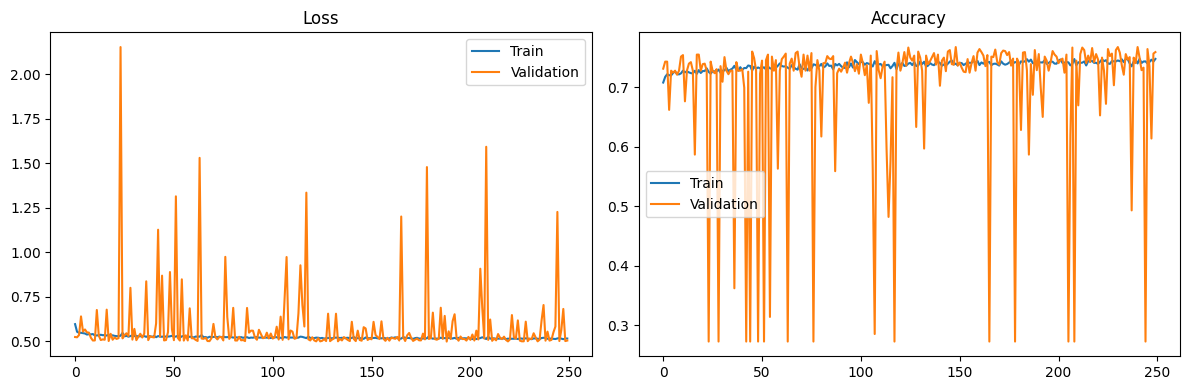

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(history['train_loss'],label='Train'); ax[0].plot(history['val_loss'],label='Validation'); ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(history['train_acc'],label='Train'); ax[1].plot(history['val_acc'],label='Validation'); ax[1].set_title('Accuracy'); ax[1].legend()
plt.tight_layout(); plt.show()


## 13. Held-out test evaluation

Report metrics from the held-out test set only. Paper reports accuracy, precision, sensitivity/recall, specificity, F1, MCC, NPV, FPR, FNR and FDR.

In [ ]:
model.eval(); y_true=[]; y_pred=[]; y_prob=[]
with torch.no_grad():
    for xb,yb in test_loader:
        logits=model(xb.to(device),A_tensor)
        probs=torch.softmax(logits,dim=1)[:,1]
        y_true.extend(yb.numpy().tolist())
        y_pred.extend(logits.argmax(1).cpu().numpy().tolist())
        y_prob.extend(probs.cpu().numpy().tolist())

tn,fp,fn,tp = confusion_matrix(y_true,y_pred,labels=[0,1]).ravel()
metrics = {
 'Accuracy':accuracy_score(y_true,y_pred),
 'Precision':precision_score(y_true,y_pred,zero_division=0),
 'Recall/Sensitivity':recall_score(y_true,y_pred,zero_division=0),
 'Specificity':tn/(tn+fp) if tn+fp else 0,
 'F1':f1_score(y_true,y_pred,zero_division=0),
 'MCC':matthews_corrcoef(y_true,y_pred),
 'NPV':tn/(tn+fn) if tn+fn else 0,
 'FPR':fp/(fp+tn) if fp+tn else 0,
 'FNR':fn/(fn+tp) if fn+tp else 0,
 'FDR':fp/(fp+tp) if fp+tp else 0,
 'AUC':roc_auc_score(y_true,y_prob) if len(set(y_true))==2 else float('nan')
}
for k,v in metrics.items(): print(f'{k:20s}: {v:.4f}')
print('\nConfusion matrix [Benign, Malignant]:', confusion_matrix(y_true,y_pred,labels=[0,1]))
print('\n',classification_report(y_true,y_pred,target_names=['Benign','Malignant'],zero_division=0))


Accuracy            : 0.7494
Precision           : 0.5556
Recall/Sensitivity  : 0.4167
Specificity         : 0.8746
F1                  : 0.4762
MCC                 : 0.3215
NPV                 : 0.7994
FPR                 : 0.1254
FNR                 : 0.5833
FDR                 : 0.4444
AUC                 : 0.7529

Confusion matrix [Benign, Malignant]: [[753 108]
 [189 135]]

               precision    recall  f1-score   support

      Benign       0.80      0.87      0.84       861
   Malignant       0.56      0.42      0.48       324

    accuracy                           0.75      1185
   macro avg       0.68      0.65      0.66      1185
weighted avg       0.73      0.75      0.74      1185



## 14. Reproducibility checklist and limitations

Before reporting results, record:
1. Exact ISIC metadata version and the 3297 selected image IDs.
2. Number of benign/malignant cases after exclusions (paper: 1497/1800).
3. Whether all lesion IDs are unique and whether near-duplicate checking was performed.
4. The seven χ²-selected features and their overlap with the paper's reported set.
5. Graph edge count at |r| > 0.2.
6. Hardware, runtime, and multiple-run mean ± standard deviation.

**Do not claim reproduction of the paper's 98.62% result unless your data subset, split, feature calculations, architecture, and experimental protocol match.** The article reports external PH2/DermNet validation, threshold ablation, model comparisons, and repeated-run statistics; these are not automatically performed in this core notebook.